<img src="https://drive.google.com/uc?export=view&id=1x-QAgitB-S5rxGGDqxsJ299ZQTfYtOhb" width=180, align="center"/>

Master's degree in Intelligent Systems

Subject: 11772 - TFM

Year: 2023-2024

Lyes Boudia

# Model 1.0 - CNN and transfer learning

In [1]:
# Connect to drive
from google.colab import drive, files
drive.mount('/content/gdrive')
%cd '/content/gdrive/MyDrive/Classifier_network'
%ls -l

# Here the path of the project folder (which is where this file is) is inserted
# into the python path.
import pathlib
import sys

Mounted at /content/gdrive
/content/gdrive/.shortcut-targets-by-id/1iLbsHLo1YdxC4JXjzCrf18VFYnCL6DLq/Classifier_network
total 178516
-rw------- 1 root root 14498212 Jun  9 12:44 CNN_Ctl.ipynb
-rw------- 1 root root 14468798 Jun  9 12:44 CNN_MobileNetV3.ipynb
-rw------- 1 root root 14459177 Jun  9 12:44 CNN_resnet50.ipynb
-rw------- 1 root root 14821511 Jun 10 09:16 CNN_Transfert_EfficientNet_B3.ipynb
-rw------- 1 root root 14927897 Jun 10 08:31 CNN_Transfert_MobileNetV3.ipynb
-rw------- 1 root root  1699586 Jun 10 02:48 CNN_Transfert_resnet50.ipynb
-rw------- 1 root root  1768580 Jun 10 06:57 CNN_Transfert_ViT.ipynb
-rw------- 1 root root 14405668 Jun  9 12:45 CNN_ViT.ipynb
-rw------- 1 root root    18197 Jun  9 12:45 helper_PR4_03.py
-rw------- 1 root root    16912 Jun  9 12:46 helper_PR4.py
-rw------- 1 root root 91681713 Jun 10 09:16 pr4_transfer_eff.pt
drwx------ 2 root root     4096 Jun 10 00:25 __pycache__/
-rw------- 1 root root    17711 Jun  9 12:46 test_helper_PR4_03.py
drwx--

In [2]:
# Import libraries
import os
from torchvision import datasets, models
import torchvision.transforms as transforms
from torch.utils.data import random_split, Dataset, WeightedRandomSampler
import numpy as np
import torch
import math
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import time
import copy
from PIL import Image
import cv2
import helper_PR4 as hp
from glob import glob
import random
from imutils import paths
from skimage import io
import pathlib
import sys
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [ ]:
# Importing and reloading the helper_PR4_02 module to ensure the latest version is used
import importlib
import helper_PR4 as hp
importlib.reload(hp)

<module 'helper_PR4' from '/content/gdrive/.shortcut-targets-by-id/18F8qhlmFseGq2zeLCkVKnC6xv1VbOmbV/Classifier/helper_PR4.py'>

In [ ]:
files.view('/content/gdrive/MyDrive/data/helper_PR4_03.py')

<IPython.core.display.Javascript object>

In [3]:
PROJECT_DIR = '/content/gdrive/MyDrive/Classifier_network'
# Global variables and setup
SEED = 4
IMG_FOLDER2 = PROJECT_DIR + "/Train"
IMG_FOLDER3 = PROJECT_DIR + "/Valid"
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

VALID_SIZE = 0.2
TEST_SIZE = 0.2

print('Using {}'.format(DEVICE))
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)
print(PROJECT_DIR)
print(IMG_FOLDER2)

Using cuda
/content/gdrive/MyDrive/Classifier_network
/content/gdrive/MyDrive/Classifier_network/Train


In [4]:
# List the contents of the IMG_FOLDER folder
print("control Folder content :", sorted(os.listdir(IMG_FOLDER2)))

# List contents of subfolders
for subfolder in sorted(os.listdir(IMG_FOLDER2)):
    print(f"{subfolder} content :", os.listdir(os.path.join(IMG_FOLDER2, subfolder)))

control Folder content : ['2step', 'Dive', 'Fusion', 'HP']
2step content : ['194_img_.png', '200_img_.png', '379_img_.png', '387_img_.png', '391_img_.png', '410_img_.png', '442_img_.png', '534_img_.png', '535_img_.png', '581_img_.png', '589_img_.png', '599_img_.png', '606_img_.png', '670_img_.png', '718_img_.png', '781_img_.png', '845_img_.png', '874_img_.png', '15003.png', '2677.png', '4.png', '837.png', '12445.png', '287_img_.png', '736_img_.png', '760_img_.png', '847_img_.png', '91_img_.png', '917_img_.png', '682_img_.png', '814_img_.png', '77_img_.png', '768_img_.png', '848_img_.png', '12433.png', '380_img_.png', '850_img_.png', '680_img_.png', '15001.png', '518_img_.png', '576_img_.png', '846_img_.png', '32_img_.png', '17_img_.png', '170_img_.png', '607_img_.png', '432_img_.png', '683_img_.png', '860_img_.png', '681_img_.png', '176_img_.png', 'flipped_4.png', 'flipped_17_img_.png', 'flipped_32_img_.png', 'flipped_77_img_.png', 'flipped_91_img_.png', 'flipped_170_img_.png', 'flippe

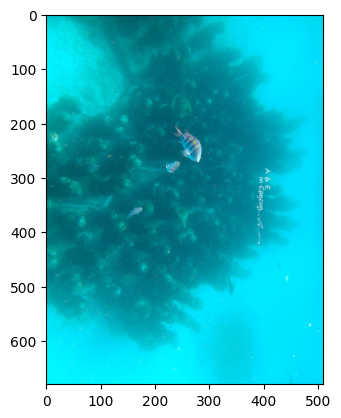

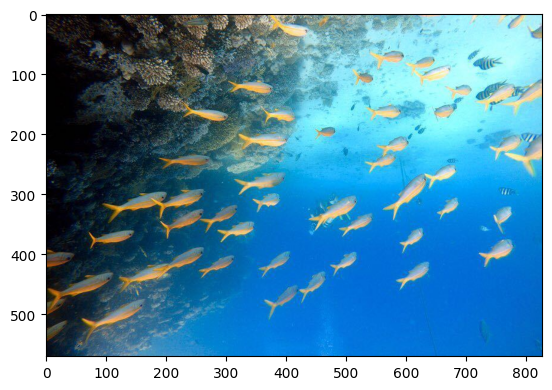

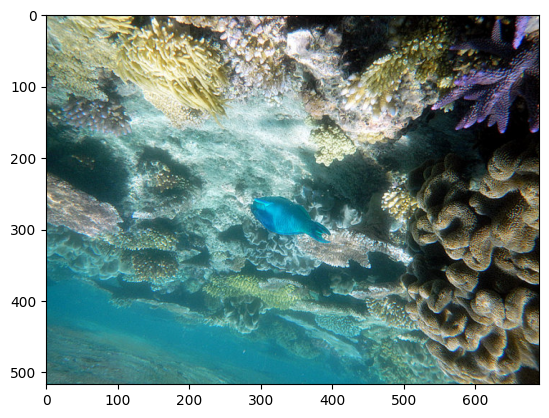

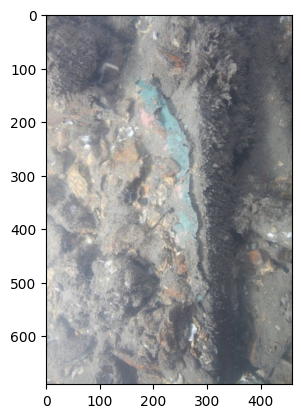

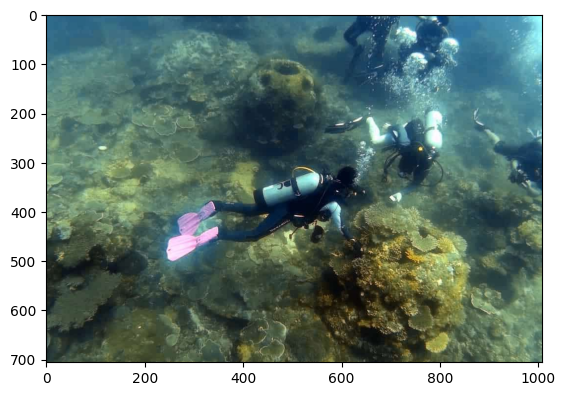

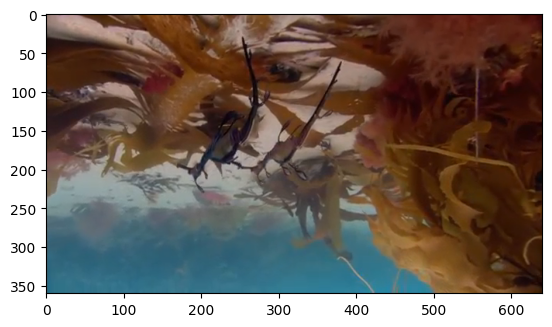

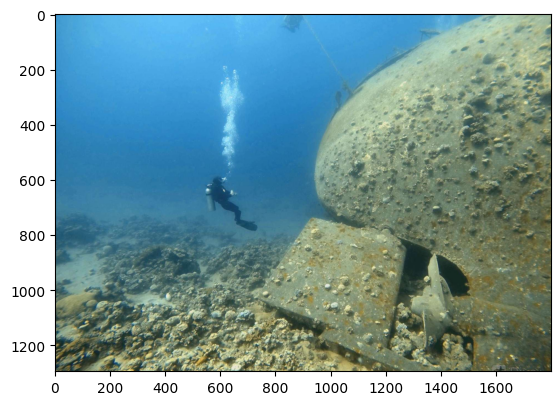

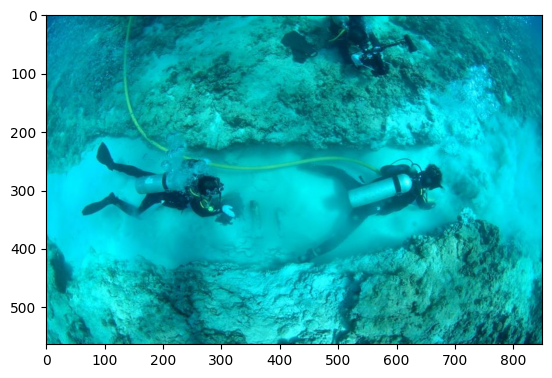

In [5]:
# Let's check some images
image_path_array = random.choices(np.array(glob(IMG_FOLDER2 + "/*/*")), k=8)

for image_path in image_path_array:  # Changed 'image' to 'image_path' for clarity

    # Read jpg image H x W x D (values between 0 and 255)
    img = cv2.imread(image_path)  # Using 'image_path' instead of 'image'

    # Check if the image was loaded successfully
    if img is not None:
        # Convert to RGB and show it
        rgb_image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(rgb_image)
        plt.show()
    else:
        print(f"Error: Could not read image at path: {image_path}")

In [6]:
# Let's analyze what we have
print('Last image shape: {}'.format(rgb_image.shape))
print('Number of images: {}'.format(len(np.array(glob(IMG_FOLDER2 + "/*/*")))))

Last image shape: (564, 850, 3)
Number of images: 1261


In [7]:
train_transform = transforms.Compose([transforms.RandomRotation(degrees=10),
                                      transforms.Resize((264, 264)),
                                      transforms.RandomCrop((224, 224)),
                                      transforms.RandomHorizontalFlip(p=0.2),
                                      transforms.ToTensor()
                                      #normalizer
                                       ])

valid_transform = transforms.Compose([transforms.Resize((264, 264)),
                                      transforms.RandomCrop((224, 224)),
                                      transforms.ToTensor() #,
                                      #normalizer
                                       ])

In [8]:
# This custom dataset class is designed to handle a collection of image paths and their corresponding labels.
# It supports applying transformations (e.g., resizing and tensor conversion) for preprocessing and augmentation.
# Additionally, it maps class names to indices and assigns labels to each image.

class CustomDataset(Dataset):
    def __init__(self, im_paths, transform=None):
        self.im_paths = im_paths  # List of image file paths
        self.transform = transform  # Transformation pipeline for preprocessing
        self.classes = []  # List to store unique class names
        self.class_to_idx = {}  # Dictionary to map class names to indices
        self.labels = []  # List to store labels corresponding to image paths
        self.resize_transform = transforms.Resize((264, 264))  # Resizing all images to a fixed size

        for im_path in sorted(im_paths):
            # Extract class name from the file path
            class_name = os.path.basename(os.path.dirname(im_path))
            if class_name not in self.classes:
                self.classes.append(class_name)

            # Assign a unique label to each class
            label = self.classes.index(class_name)

            # Populate the class-to-index dictionary
            if class_name not in self.class_to_idx:
                self.class_to_idx[class_name] = label

            # Append the label to the labels list
            self.labels.append(label)

            # Define a default transformation if none is provided
            if transform is None:
                self.transform = transforms.ToTensor()
            else:
                self.transform = transform

    def __len__(self):
        # Return the total number of images in the dataset
        return len(self.labels)

    def __getitem__(self, idx):
        # Retrieve image path and corresponding label for the given index
        image_path = self.im_paths[idx]
        image = Image.open(image_path).convert('RGB')  # Open the image and convert it to RGB
        image = self.resize_transform(image)  # Resize the image to a fixed size

        label = self.labels[idx]  # Get the corresponding label

        # Apply additional transformations if specified
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label)  # Return the processed image and its label as a tensor

In [9]:
# Process IMG_FOLDER2
folder_path2 = IMG_FOLDER2
subfolders2 = sorted(os.listdir(folder_path2))
im_p2 = []
for subfolder in subfolders2:
    subfolder_path = os.path.join(folder_path2, subfolder)
    if os.path.isdir(subfolder_path):
        subfolder_images = [
            os.path.join(subfolder_path, f)
            for f in os.listdir(subfolder_path)
            if os.path.isfile(os.path.join(subfolder_path, f))
        ]
        im_p2.extend(subfolder_images)
print(len(im_p2))  # Total number of image files in IMG_FOLDER2

1261


In [10]:
full_dataset2 = CustomDataset(im_p2)
print(type(full_dataset2))

<class '__main__.CustomDataset'>


In [11]:
folder_path3 = IMG_FOLDER3
subfolders3 = sorted(os.listdir(folder_path3))
im_p3 = []
for subfolder in subfolders3:
    subfolder_path = os.path.join(folder_path3, subfolder)
    if os.path.isdir(subfolder_path):
        subfolder_images = [
            os.path.join(subfolder_path, f)
            for f in os.listdir(subfolder_path)
            if os.path.isfile(os.path.join(subfolder_path, f))
        ]
        im_p3.extend(subfolder_images)
print(len(im_p3))  # Total number of image files in IMG_FOLDER3

162


In [12]:
full_dataset3 = CustomDataset(im_p3)
print(type(full_dataset2))

<class '__main__.CustomDataset'>


In [13]:
print(len(full_dataset2))
n_t1 = 1
n_train = len(full_dataset2) - n_t1
train_dataset,  t2_dataset = random_split(full_dataset2,
                                                 [n_train, n_t1])

1261


In [14]:
print(len(full_dataset3))
n_t3 = 1
n_valid = len(full_dataset3) - n_t3
valid_dataset,  t3_dataset = random_split(full_dataset3,
                                                 [n_valid, n_t3])

162


In [15]:
print(type(train_dataset))
print(len(train_dataset))
print(len(valid_dataset))

<class 'torch.utils.data.dataset.Subset'>
1260
161


In [16]:
# Create a deep copy of the train dataset to preseve integrity of the original dataset
train_dataset = copy.deepcopy(train_dataset)

# Apply training transformations to train dataset
train_dataset.dataset.transform = train_transform

# # Apply validation transformations to valid dataset
valid_dataset.dataset.transform = valid_transform

# # Apply test transformations to test dataset
#test_dataset.dataset.transform = test_transform

In [17]:
# Check that both transformations do not refer to the same thing
print(train_dataset.dataset.transform is valid_dataset.dataset.transform)
# however, the validation and test ones remain the same
#print(valid_dataset.dataset.transform is test_dataset.dataset.transform)

False


In [18]:
# Set the number of workers for parallel data loading
num_workers = 2

# Set the batch size for loading data in chunks
batch_size = 64

# Create a DataLoader for the training set with shuffling enabled to randomize the order of data,
# which helps in better model generalization during training.
train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=batch_size,
                                           shuffle=True,
                                           num_workers=num_workers)

# Create a DataLoader for the validation set without shuffling since the validation data should remain consistent
# and not be randomized. The model's performance should be evaluated on the same data.
valid_loader = torch.utils.data.DataLoader(valid_dataset,
                                           batch_size=batch_size,
                                           shuffle=False,
                                           num_workers=num_workers)

# Create a DataLoader for the test set without shuffling to ensure the test data remains in the same order,
# providing a consistent evaluation benchmark across runs.
test_loader = torch.utils.data.DataLoader(valid_dataset,
                                          batch_size=167,
                                          shuffle=False,
                                          num_workers=num_workers)

In [19]:
# Create an iterator from the train_loader to fetch batches of data
data_iter = iter(train_loader)

# Get the next batch of images and labels from the iterator
images, labels = next(data_iter)

# Print the shape of the batch (number of images, channels, height, width)
print('Batch shape: {}'.format(images.data.shape))

# Print the shape of the first image in the batch (channels, height, width)
print('Image shape: {}'.format(images.data[0].shape))

# Print the minimum pixel value in the first image of the batch
print('Minimum image value: {}'.format(images.data[0].min()))

# Print the maximum pixel value in the first image of the batch
print('Maximum image value: {}'.format(images.data[0].max()))

# Print the mean pixel values across the batch for each channel (Red, Green, Blue)
print('Batch means: {}'.format(images.data.mean(axis=(0,2,3))))

# Print the standard deviation of pixel values across the batch for each channel
print('Batch std: {}'.format(images.data.std(axis=(0,2,3))))

Batch shape: torch.Size([64, 3, 224, 224])
Image shape: torch.Size([3, 224, 224])
Minimum image value: 0.0
Maximum image value: 1.0
Batch means: tensor([0.2982, 0.5108, 0.4933])
Batch std: tensor([0.1979, 0.2091, 0.2136])


In [20]:
# (b x D x H x W) = (batch x Depth x Height x Width) = (b x 3 x 299 x 299)
print(images.shape)
print(labels.shape)

torch.Size([64, 3, 224, 224])
torch.Size([64])


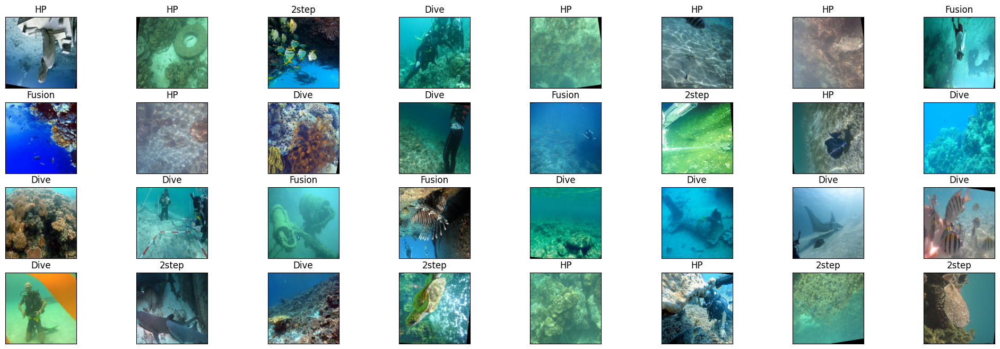

In [21]:
# Let's look at some of those images. And observe how in some the applied rotation
# is perceived

fig = plt.figure(figsize=(25, 8))
bs = 32 if batch_size > 32 else batch_size
for k in range(bs):
    ax = fig.add_subplot(int(np.ceil(bs / 8)), 8, k + 1, xticks=[], yticks=[])

    img = images[k].numpy()


    ax.imshow(np.transpose(img, (1, 2, 0)))
    ax.set_title(train_loader.dataset.dataset.classes[labels[k].item()])

In [22]:
# Clears the GPU cache to release unused memory allocated by PyTorch
torch.cuda.empty_cache()

# Sets the random seed for NumPy's random number generator to ensure reproducibility
np.random.seed(SEED)

# Sets the random seed for PyTorch's random number generator for reproducibility
torch.manual_seed(SEED)

In [23]:
# We arrange the data loaders in a single object
loaders = {'train': train_loader, 'valid': valid_loader, 'test': test_loader}

In [24]:
n_outputs_fc = 4  # Your specified output classes

# Load pretrained ResNet50
model_transfer = models.resnet50(weights='DEFAULT')

# Freeze all layers initially
for param in model_transfer.parameters():
    param.requires_grad = False

# Unfreeze selective layers (last 2 bottleneck blocks)
for param in model_transfer.layer3.parameters():
    param.requires_grad = True
for param in model_transfer.layer4.parameters():
    param.requires_grad = True

# Get the number of input features for the classifier
num_ftrs = model_transfer.fc.in_features

# Custom classifier (modified for ResNet)
custom_classifier = nn.Sequential(
    nn.Linear(num_ftrs, 512),
    nn.BatchNorm1d(512),
    nn.GELU(),
    nn.Dropout(0.4),

    nn.Linear(512, 384),
    nn.BatchNorm1d(384),
    nn.GELU(),
    nn.Dropout(0.3),

    nn.Linear(384, 256),
    nn.BatchNorm1d(256),
    nn.GELU(),
    nn.Dropout(0.1),

    nn.Linear(256, n_outputs_fc)
)

# Replace the fully connected layer only
model_transfer.fc = custom_classifier


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


In [25]:
total_params = sum(p.numel() for p in model_transfer.parameters())
trainable_params = sum(p.numel() for p in model_transfer.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 24,856,004
Trainable parameters: 23,411,076


In [26]:
# Transfer the model to GPU
model_transfer.to(DEVICE)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [27]:
# The name of the model done by transfer learning
FILENAME = 'pr4_transfer_res.pt'

In [28]:
optimizer = torch.optim.SGD(
    model_transfer.parameters(),
    lr=0.005,
    momentum=0.9,
    nesterov=True,
    weight_decay=2e-4
)

In [29]:
# The loss function
criterion = nn.CrossEntropyLoss().to(DEVICE)

In [30]:
# Do the training
n_epochs = 60
model_transfer, tr_data = hp.train(n_epochs, loaders, model_transfer, optimizer, criterion, FILENAME)

Epoch:  1 | Train: 1.3177 | Val: 1.2977 | F1: 0.4875 | LR: 5.0e-03
★ New best F1: 0.4875
Epoch:  2 | Train: 1.0363 | Val: 1.1174 | F1: 0.5342 | LR: 5.0e-03
★ New best F1: 0.5342
Epoch:  3 | Train: 0.7902 | Val: 1.1956 | F1: 0.5264 | LR: 5.0e-03
Epoch:  4 | Train: 0.5774 | Val: 1.3106 | F1: 0.4946 | LR: 5.0e-03
Epoch:  5 | Train: 0.3930 | Val: 1.2811 | F1: 0.5305 | LR: 5.0e-03
Epoch:  6 | Train: 0.2928 | Val: 1.4011 | F1: 0.5439 | LR: 5.0e-03
★ New best F1: 0.5439
Epoch:  7 | Train: 0.2119 | Val: 1.4907 | F1: 0.5233 | LR: 5.0e-03
Epoch:  8 | Train: 0.1522 | Val: 1.5785 | F1: 0.5377 | LR: 5.0e-03
Epoch:  9 | Train: 0.1061 | Val: 1.6363 | F1: 0.5685 | LR: 5.0e-03
★ New best F1: 0.5685
Epoch: 10 | Train: 0.0856 | Val: 1.6037 | F1: 0.5813 | LR: 5.0e-03
★ New best F1: 0.5813
Epoch: 11 | Train: 0.0856 | Val: 1.6849 | F1: 0.5727 | LR: 5.0e-03
Epoch: 12 | Train: 0.0578 | Val: 1.8674 | F1: 0.5244 | LR: 5.0e-03
Epoch: 13 | Train: 0.0642 | Val: 1.8354 | F1: 0.5413 | LR: 5.0e-03
Epoch: 14 | Train: 

In [31]:
# Load the checkpoint
model_transfer, optimizer, checkpoint = hp.trained_load(FILENAME, model_transfer, optimizer)

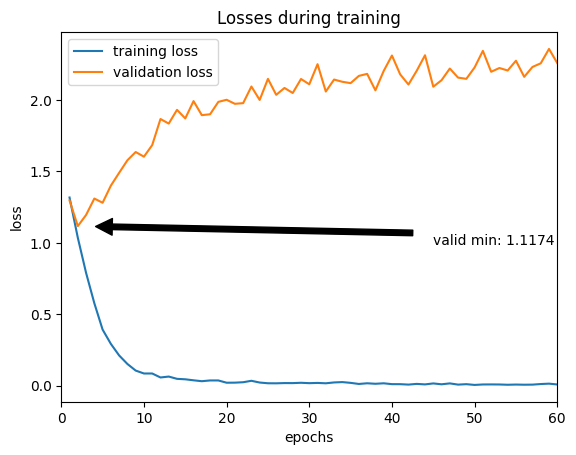

In [32]:
# Training and validation plots
hp.plot_checkpoint({'tr_loss_list': tr_data[0], 'vl_loss_list': tr_data[1]})

In [33]:
# Test the model
accuracy, test_loss, accuracy_std, f1, precision, recall, f1_std, precision_std, recall_std, outputs = hp.do_test(model_transfer, loaders, criterion)

# Print the metrics
print(f"Test Loss: {test_loss:.2f}")
print(f"Accuracy: {accuracy:.2f} ± {accuracy_std:.2f}")
print(f"F1 Score: {f1:.2f} ± {f1_std:.2f}")
print(f"Precision: {precision:.2f} ± {precision_std:.2f}")
print(f"Recall: {recall:.2f} ± {recall_std:.2f}")

Test Loss: 2.09
Accuracy: 0.58 ± 0.00
F1 Score: 0.55 ± 0.21
Precision: 0.58 ± 0.06
Recall: 0.58 ± 0.28


# Probability

In [34]:
# We select the first iteration of the test dataloader
data_iter = iter(test_loader)
images, labels = next(data_iter)

In [35]:
# We apply a test step and obtain logits
_, output = hp.test_pass(images, labels, model_transfer, criterion)
print(output.shape)

torch.Size([161, 4])


In [36]:
# We apply the activation layer and get probabilities
output_prob = torch.softmax(output, dim=1)

In [37]:
# To check that there was no error, let's look at the result of the first
# image. It is a vector of probabilities.
print(output_prob[0])

tensor([0.0150, 0.2062, 0.4759, 0.3028], device='cuda:0')


In [38]:
# The sum of the 5 probabilities associated with this image should be equal
# to 1, since there are only these 5 possible outputs.
print(torch.sum(output_prob[0]).item())

1.0000001192092896


In [39]:
# The indices corresponding to the maximum values are obtained
_, pred_labels = torch.max(output, dim=1)

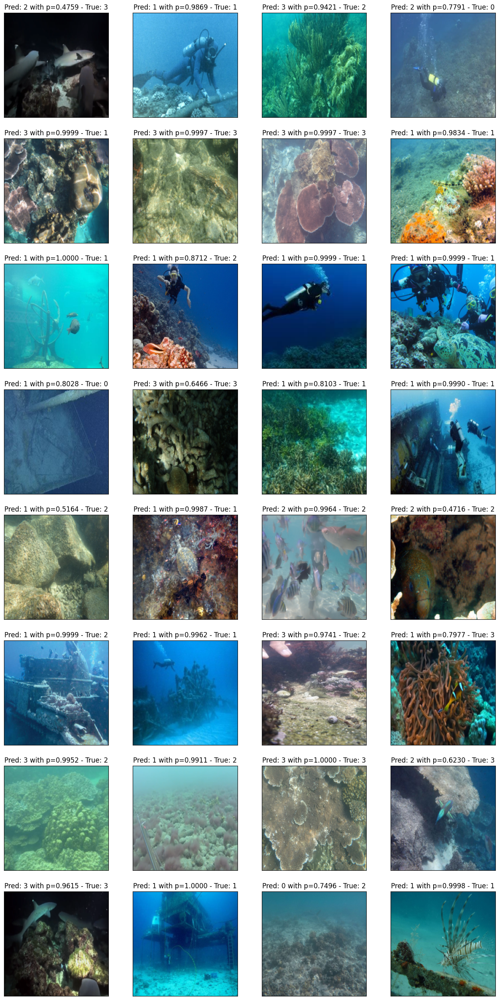

In [40]:
#  Viewing prediction results in a batch with class label, ( default is 32, ajustable as needed)
fig = plt.figure(figsize=(16, 32))
bs = 32 if len(labels) > 32 else len(labels)
for k in range(bs):
    ax = fig.add_subplot(int(np.ceil(bs / 4)), 4, k + 1, xticks=[], yticks=[])

    # Display the image in color
    ax.imshow(images[k].permute(1, 2, 0).numpy())  # Permute if the image is in (C, H, W) format

    # The predicted label, the probability, and the correct label are included
    ax.set_title('Pred: {} with p={:.4f} - True: {}'.format(
        pred_labels[k].item(),
        output_prob[k, pred_labels[k].item()].item(),
        str(labels[k].item())))

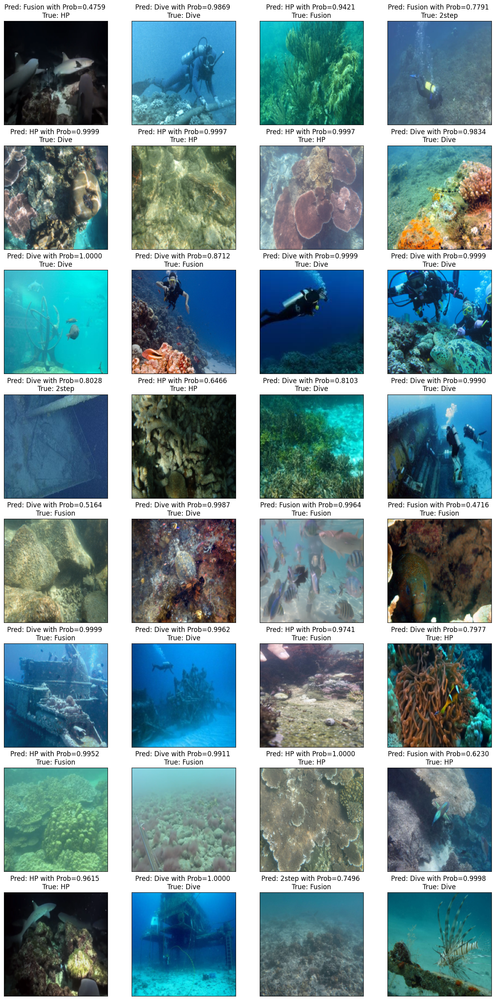

In [41]:
#  Viewing prediction results in a batch with class name, ( default is 32, ajustable as needed)
fig = plt.figure(figsize=(16, 32))
bs = 32 if len(labels) > 32 else len(labels)

for k in range(bs):
    ax = fig.add_subplot(int(np.ceil(bs / 4)), 4, k + 1, xticks=[], yticks=[])

    # Display the image in color
    ax.imshow(images[k].permute(1, 2, 0).numpy())  # Permute if the image is in (C, H, W) format

    # Get the predicted and true class names from the dataset
    pred_class = test_loader.dataset.dataset.classes[pred_labels[k].item()]
    true_class = test_loader.dataset.dataset.classes[labels[k].item()]

    # Display the predicted class name, probability, and the true class name
    ax.set_title('Pred: {} with Prob={:.4f} \nTrue: {}'.format(
        pred_class,
        output_prob[k, pred_labels[k].item()].item(),
        true_class))
    plt.subplots_adjust(hspace=0.2)

# Confusion matrix

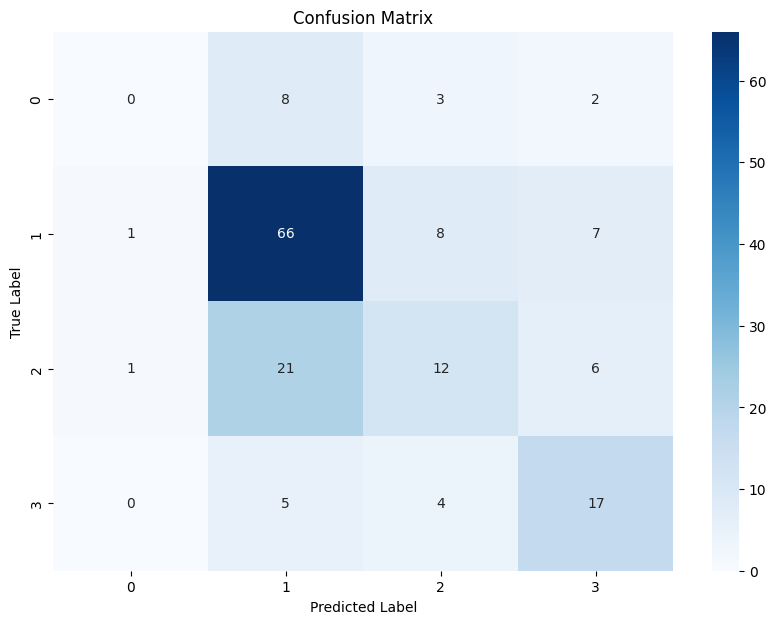

In [42]:

# Move tensors to CPU before converting to numpy
labels_cpu = labels.cpu().numpy()
pred_labels_cpu = pred_labels.cpu().numpy()

# Compute confusion matrix
cm = confusion_matrix(labels_cpu, pred_labels_cpu)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(cm.shape[0]), yticklabels=range(cm.shape[0]))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

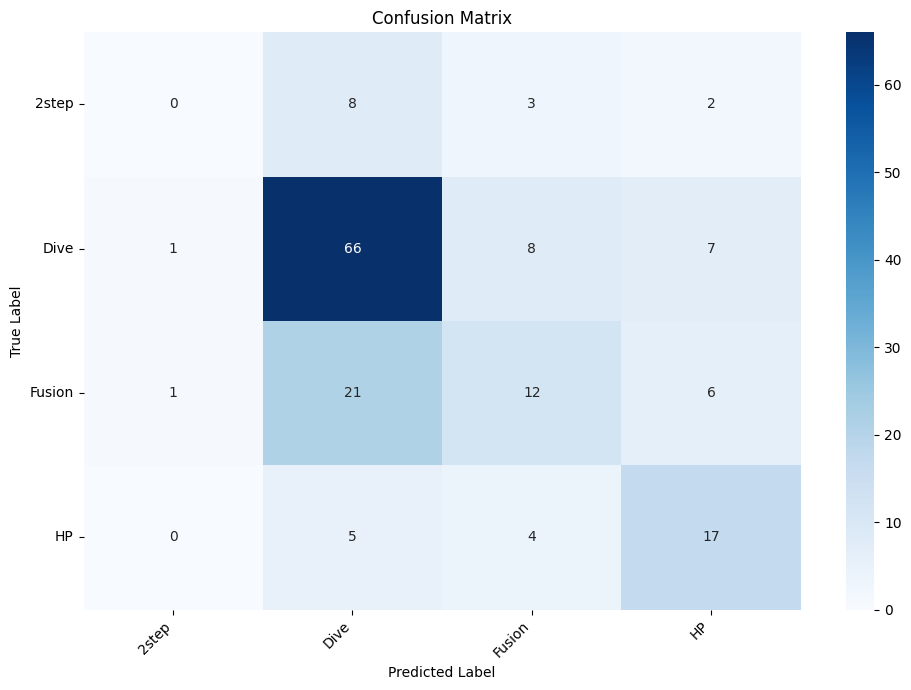

In [43]:
# Move tensors to CPU before converting to numpy
labels_cpu = labels.cpu().numpy()
pred_labels_cpu = pred_labels.cpu().numpy()

# Compute confusion matrix
cm = confusion_matrix(labels_cpu, pred_labels_cpu)

# Get class names from the dataset
class_names = test_loader.dataset.dataset.classes

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

# Rotate x-axis labels for better readability if needed
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()